# Analyze latest data from WandB

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from imlff.analysis.base import fetch_runs_df
from schnetpack.md.data import HDF5Loader

from collections import defaultdict

from imlff.loading import artifact_or_run_cached

import pandas as pd
import wandb

from imlff.common.util import proj_path
import os

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

from collections import defaultdict

api = wandb.Api()

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


### Explicit sims

In [91]:
### Explicit ###


save_name = 'mar-04/md-tol-search-line-Ac-Ala3-NHMe-explicit'

pat = proj_path('result_summary', save_name+'.csv')
if os.path.exists(pat) and False:
    sims_df_full = pd.read_csv(pat)
else:
    kwargs = {
        'molecule_config.molecule_name': 'Ac-Ala3-NHMe',
        # 'model_config.model_tag': 'qcml-group/dev-v10/model-4ehmqw9w:v3392',
        # 'tags': 'tol search',
        'tags': 'explicit',
        'molecule_config.equil_steps': 10000,
        
        # 'md_config.langevin_time_constant': np.nan,
        # 'md_config.langevin_time_constant': 0,
        # 'md_config.langevin_time_constant': 100,
        # 'train.n_interactions': 1,
    }
    fetched = sims_df_full = fetch_runs_df(
        project_name='md-v7-test',
        max_runs=None,
        **kwargs,
        fix=False
    )
    
    for col in ['model_config', 'molecule_config', 'md_config', 'train']:
        sims_df_full = pd.concat([
            sims_df_full[col].apply(pd.Series).add_prefix(f"{col}__"),
            sims_df_full.drop([col], axis=1),
        ], axis=1)
    
    for pad_col in ['model_config__forw_tol', 'model_config__back_tol']:
        assert pad_col not in sims_df_full.columns
        sims_df_full[pad_col] = -sims_df_full.train__n_interactions

    # if we accidentally double, use only the first
    valid_mask = (sims_df_full._step==100_000) ^ (sims_df_full._step==99_999)
    print(sims_df_full[~valid_mask]._step.value_counts())
    sims_df_full = sims_df_full[valid_mask]
    sims_df_full = sims_df_full.sort_values('_timestamp').groupby(['train__n_interactions', 'model_config__model_tag', 'md_config__langevin_time_constant', 'seed']).first().reset_index()
    sims_df_full.to_csv(pat)


print(len(sims_df_full))
for c in sims_df_full.columns:
    if 'train' in c: continue
    print(c)

Fetching runs from md-v7-test with filters {'config.molecule_config.molecule_name': 'Ac-Ala3-NHMe', 'config.molecule_config.equil_steps': 10000, 'tags': 'explicit'}
Found 323 runs.
after filter: 323


100%|██████████████████████████████| 323/323 [00:00<00:00, 19634.77it/s]

_step
0.0        3
26205.0    1
5549.0     1
5096.0     1
5572.0     1
5940.0     1
4674.0     1
1447.0     1
Name: count, dtype: int64


300
model_config__model_tag
md_config__langevin_time_constant
seed
md_config__Init
md_config__timestep
md_config__integrator
md_config__temperature
md_config__initial_temperature
molecule_config__fmax
molecule_config__stepsmax
molecule_config__equil_steps
molecule_config__molecule_idx
molecule_config__molecule_name
molecule_config__equil_md_config
molecule_config__model_config_relax
_runtime
_step
_timestamp
kinetic_energy/molecule_01/r01
potential_energy/molecule_01/r01
temperature/molecule_01/r01
termination
total_energy/molecule_01/r01
runtime
version
proj_path
md_version
slurm_job_id
warmstart_mode
model_config_description
name
run_id
state
run
model_config__forw_tol
model_config__back_tol


In [94]:
sims_df_full.groupby(['train__n_interactions', 'model_config__model_tag', 'md_config__langevin_time_constant'])._step.agg(list)

train__n_interactions  model_config__model_tag                  md_config__langevin_time_constant
1                      qcml-group/dev-v10/model-bu7zjx44:v2422  0                                    [100000.0, 100000.0, 100000.0, 100000.0, 10000...
                                                                100                                  [99999.0, 99999.0, 99999.0, 99999.0, 99999.0, ...
                                                                1000                                 [99999.0, 99999.0, 99999.0, 99999.0, 99999.0, ...
                                                                10000                                [99999.0, 99999.0, 99999.0, 99999.0, 99999.0, ...
2                      qcml-group/dev-v10/model-55ps8a42:v825   0                                    [99999.0, 99999.0, 99999.0, 99999.0, 99999.0, ...
                                                                100                                  [99999.0, 99999.0, 99999.0, 99999.0, 99999.0, 

In [95]:
filtered = sims_df_full[(sims_df_full._step==100_000) ^ (sims_df_full._step==99_999)]
filtered = sims_df_full[(sims_df_full._step>0)]
existing_seeds = filtered.groupby(['train__n_interactions', 'model_config__model_tag', 'md_config__langevin_time_constant']).seed

existing_seeds.agg(['nunique', sorted])

nunique  \
train__n_interactions model_config__model_tag                 md_config__langevin_time_constant            
1                     qcml-group/dev-v10/model-bu7zjx44:v2422 0                                       15   
                                                              100                                     15   
                                                              1000                                    15   
                                                              10000                                   15   
2                     qcml-group/dev-v10/model-55ps8a42:v825  0                                       15   
                                                              100                                     15   
                                                              1000                                    15   
                                                              10000                                   15   
3                     qcml-group/dev-v10/model-j2nx77a8:v644  0                                       15   
                                                              100                                     15   
                                                              1000                                    15   
                                                              10000                                   15   
4                     qcml-group/dev-v10/model-gcmp3fx6:v325  0                                       15   
                                                              100                                     15   
                                                              1000                                    15   
                                                              10000                                   15   
5                     qcml-group/dev-v10/model-y3j2gbxj:v346  0                                       15   
                                                              100                                     15   
                                                              1000                                    15   
                                                              10000                                   15   

                                                                                                                                            sorted  
train__n_interactions model_config__model_tag                 md_config__langevin_time_constant                                                     
1                     qcml-group/dev-v10/model-bu7zjx44:v2422 0                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              100                                [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              1000                               [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              10000                              [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
2                     qcml-group/dev-v10/model-55ps8a42:v825  0                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              100                                [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              1000                               [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              10000                              [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
3                     qcml-group/dev-v10/model-j2nx77a8:v644  0                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...  
                                                              100                

In [96]:
missing = existing_seeds.unique().apply(lambda existing: [s for s in range(15) if s not in existing]).reset_index().explode('seed')
missing = missing[~missing.seed.isna()]
print('missing =', tuple(tuple(r[1:]) for r in missing.to_numpy().tolist()))
print(len(missing))
missing

missing = ()
0


,train__n_interactions,model_config__model_tag,md_config__langevin_time_constant,seed


### Implicit sims

In [3]:
save_name = 'feb-16/md-tol-search-line-Ac-Ala3-NHMe'

pat = proj_path('result_summary', save_name+'.csv')
if os.path.exists(pat):
    sims_df_full = pd.read_csv(pat)
else:
    assert 0
    kwargs = {
        'molecule_config.molecule_name': 'Ac-Ala3-NHMe',
        'model_config.model_tag': 'qcml-group/dev-v10/model-4ehmqw9w:v3392',
        # 'tags': 'tol search',
        'tags': 'tol search line',
        'molecule_config.equil_steps': 10000,
        # 'md_config.langevin_time_constant': np.nan,
        # 'md_config.langevin_time_constant': 100,
    }
    sims_df_full = fetch_runs_df(
        project_name='md-v7-test',
        max_runs=None,
        **kwargs,
        fix=False
    )
    
    for col in ['model_config', 'molecule_config', 'md_config', 'train']:
        sims_df_full = pd.concat([
            sims_df_full[col].apply(pd.Series).add_prefix(f"{col}__"),
            sims_df_full.drop([col], axis=1),
        ], axis=1)
    
    sims_df_full.to_csv(pat)
for c in sims_df_full.columns:
    if 'train' in c: continue
    print(c)

Unnamed: 0
md_config__timestep
md_config__integrator
md_config__temperature
md_config__initial_temperature
md_config__langevin_time_constant
md_config__Init
molecule_config__fmax
molecule_config__stepsmax
molecule_config__equil_steps
molecule_config__molecule_idx
molecule_config__molecule_name
molecule_config__equil_md_config
molecule_config__model_config_relax
model_config__back_tol
model_config__forw_tol
model_config__model_tag
model_config__back_solver
model_config__forw_solver
model_config__back_max_iter
model_config__forw_max_iter
model_config__implicit_diff
model_config__warmstart_configs
_runtime
_step
_timestamp
back_iterations
back_res_0
back_res_1
back_res_2
back_res_3
back_res_4
forw_iterations
forw_res_0
forw_res_1
forw_res_2
forw_res_3
forw_res_4
kinetic_energy/molecule_01/r01
potential_energy/molecule_01/r01
temperature/molecule_01/r01
termination
total_energy/molecule_01/r01
runtime
seed
version
proj_path
md_version
slurm_job_id
model_config_description
name
run_id
state

In [4]:
sims_df_full = sims_df_full.sort_values(by=['model_config__forw_tol', 'model_config__back_tol', ]).reset_index(drop=True)
sims_df_full[['model_config__forw_tol', 'model_config__back_tol', '_step', 'md_config__langevin_time_constant', 'run_id']].head()

,model_config__forw_tol,model_config__back_tol,_step,md_config__langevin_time_constant,run_id
0,0.0,0.0,99999,NaN,34l6lcpy
1,0.0,0.0,99999,NaN,mco52oyo
2,0.0,0.0,99999,1000.0,l13fexxt
3,0.0,0.0,99999,1000.0,6wrrsy7x
4,0.0,0.0,99999,1000.0,n6lq8cpf


### Loading

In [6]:
def load_data_for_run(proj_p, keys):
    res = dict()
    log_file = proj_path(proj_p + '.hdf5')
    assert os.path.exists(log_file)
    l = None
    with HDF5Loader(log_file, skip_initial=0) as data:
        for k in keys:
            if 'temperature' in k:
                d = data.get_temperature()
            elif 'kinetic_energy' in k:
                d = data.get_kinetic_energy()
            elif 'potential_energy' in k:
                d = data.get_potential_energy()
            else:
                try:
                    d = np.squeeze(data.properties[k])
                except:
                    d = np.full_like(d, np.nan)
            l = l or len(d)
            assert l==len(d)
            res[k]=d
    res['_step'] = np.arange(l)
    return pd.DataFrame(res)

In [7]:
if 'store' not in locals():
    print('Initializing store.')
    store = dict()

Initializing store.


In [ ]:

q = ' and '.join([
    # 'md_config__langevin_time_constant == 100',
    # 'md_config__langevin_time_constant == 1_000',
    # 'md_config__langevin_time_constant == 10_000',
    # 'md_config__langevin_time_constant.isnull()',
    # '`model_config__forw_tol`==`model_config__back_tol` and _step==99999',
    # '_step==99999',

    #  'model_config__forw_tol==0.1',
    #  'model_config__forw_tol==0.',
    
    # 'model_config__forw_tol<0.1',
    # 'model_config__forw_tol==0.01',
    
    # 'model_config__forw_tol==-1',
    '(_step in [99_999, 100_000])'
])
qs = (sims_df_full.query(q) if q else sims_df_full)

load_keys = [
    'temperature/molecule_01/r01',
    'potential_energy/molecule_01/r01',
    'kinetic_energy/molecule_01/r01',
    'forw_iterations',
    'back_iterations',
]

for i, row in tqdm(qs.iterrows(), total=len(qs)):
    if row.run_id not in store or row._step > store[row.run_id].index.max()+1:
        if row.run_id in store:
            print('Reloading:', row.run_id)
            print(row._step, store[row.run_id].index.max()+1, row._step > store[row.run_id].index.max()+1)
        if False:
            data_for_run = run.history(samples=1000, keys=list(keys.keys()))
        else:
            data_for_run = load_data_for_run(row.proj_path, load_keys)
        store[row.run_id] = data_for_run

In [ ]:
only_load = True
only_load = False

plot_lines = not only_load and True
plot_termination_temp = not only_load and True

q = ' and '.join([
    # 'md_config__langevin_time_constant == 1_000',
    # 'md_config__langevin_time_constant == 10_000',
    # 'md_config__langevin_time_constant.isnull()',
    
    # '`model_config__forw_tol`==`model_config__back_tol`,
    # '_step==99999',

    #  'model_config__forw_tol==0.1',
    # 'model_config__forw_tol==0.01',
    #  'model_config__forw_tol==0.',
    
    'model_config__forw_tol<0.1',
])


lines_starting = 0

markersize=100

# Boolean option to split by ltc
split_by_ltc = True  # Set to True to create separate columns for each ltc value

plot_alpha = 1.
keys = {('potential_energy/molecule_01/r01', 'kinetic_energy/molecule_01/r01',): (-50, 500),}
scale = 1.
lines_starting = 0
plot = save_tag = 'total_energy'

if True: # load
    qs = (sims_df_full.query(q) if q else sims_df_full).copy()
    # ltc_str = lambda x: 'NVE' if np.isnan(x) else f'LTC = {int(x/1000)}ps'
    # qs.md_config__langevin_time_constant = qs.md_config__langevin_time_constant.apply(ltc_str)
    qs.md_config__langevin_time_constant = qs.md_config__langevin_time_constant.fillna(np.inf)
    print(f"Plotting {len(qs)} runs")

    # descending order of preference
    scatter_measurements = ['d.first_step_above.1_0', 'd.first_step_above.0_9']

    n_keys = len(keys)

    if split_by_ltc:
        unique_ltcs = sorted(qs['md_config__langevin_time_constant'].unique())
        n_cols = len(unique_ltcs)
        n_rows = n_keys
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(5*n_cols*scale, 4*n_rows*scale))
        if n_rows == 1 and n_cols == 1:
            axs = np.array([[axs]])
        elif n_rows == 1:
            axs = axs.reshape(1, -1)
        elif n_cols == 1:
            axs = axs.reshape(-1, 1)
    else:
        fig, axs = plt.subplots(1, n_keys, figsize=(5*n_keys*scale, 4*scale))
        if n_keys == 1:
            axs = [axs]

    # Get unique forw_tol values from dataframe and create color map
    unique_forw_tols = sorted(qs['model_config__forw_tol'].unique())
    forw_tol_to_color = {tol: plt.cm.viridis(i / max(1, (len(unique_forw_tols) - 1)))
                        for i, tol in enumerate(unique_forw_tols)}

### Avg store

In [101]:
# Get unique forw_tol values from dataframe and create color map
unique_forw_tols = sorted(qs['model_config__forw_tol'].unique())
forw_tol_to_color = {tol: plt.cm.viridis(i / max(1, (len(unique_forw_tols) - 1)))
                    for i, tol in enumerate(unique_forw_tols)}
print(forw_tol_to_color)

{np.int64(-5): (np.float64(0.267004), np.float64(0.004874), np.float64(0.329415), np.float64(1.0)), np.int64(-4): (np.float64(0.229739), np.float64(0.322361), np.float64(0.545706), np.float64(1.0)), np.int64(-3): (np.float64(0.127568), np.float64(0.566949), np.float64(0.550556), np.float64(1.0)), np.int64(-2): (np.float64(0.369214), np.float64(0.788888), np.float64(0.382914), np.float64(1.0)), np.int64(-1): (np.float64(0.993248), np.float64(0.906157), np.float64(0.143936), np.float64(1.0))}


In [ ]:
log_alpha = 0.01
log_alpha = 0.001

## If something is wrogn clear cache:
# artifact_or_run_cached.cache_clear()

termination_store = defaultdict(dict)
avg_store = defaultdict(dict)

for i, row in tqdm(qs.iterrows()): # plot, gather bond breaking events
        
    run = row['run']
    step = row['_step']
    forw_tol = row['model_config__forw_tol']
    back_tol = row['model_config__back_tol']
    ltc = row['md_config__langevin_time_constant']
    
    # run = row.run
    # if type(run) is str:
    run = artifact_or_run_cached(f'qcml-group/md-v7-test/{row.run_id}', run=True)
    try:
        termination = run.summary.termination
    except Exception as e:
        print(e)
        termination = dict()
    print(termination)
    
    data_for_run = store.get(row['run_id'])
    assert data_for_run is not None
    
    
    latest_termination_step = latest_termination_temperature = None
    smooth_temp = data_for_run['temperature/molecule_01/r01'].ewm(alpha=log_alpha).mean()
    for label, step in sorted(termination.items()): # sort such that highest threshold comes last (for avg temp we want to use 0_9 or 1_0)
        prefix = 'd.first_step_above.'
        
        if label.startswith(prefix):
            latest_termination_step = step
            short_label = label[len(prefix):]
            
            latest_termination_temperature = smooth_temp[latest_termination_step].item()
            termination_store[(row.run_id, forw_tol, back_tol)][f"{short_label}"] = dict(
                ltc=ltc,
                step=latest_termination_step,
                temperature=latest_termination_temperature, 
                
            )

    else:
        # Calculate average iterations
        x_full = data_for_run['_step'][~np.isnan(data_for_run['_step'])]
        if latest_termination_step is None:
            valid_mask = np.ones(len(x_full), dtype=bool)
        else:
            valid_mask = x_full <= latest_termination_step
            
        # # restrict to last 25 percent
        # start_of_end = (latest_termination_step or len(x_full)) * .75
        # valid_mask &= x_full > start_of_end
        
        def take_mean(lbl):
            postfix = '/molecule_01/r01'
            if lbl in data_for_run:
                x = data_for_run[lbl]
            elif lbl+postfix in data_for_run:
                x = data_for_run[lbl+postfix]
            else:
                return np.array([np.nan, np.nan])
            
            return np.array([x[0], x[valid_mask & ~np.isnan(x)].mean()])
        
        avg_iterations=(take_mean('forw_iterations') + take_mean('back_iterations'))/2
        k_e=take_mean('kinetic_energy')
        p_e=take_mean('potential_energy')
        t_e=take_mean('kinetic_energy') + take_mean('potential_energy')
        temperature=take_mean('temperature')
        
        avg_store[(row.run_id, forw_tol, back_tol)] = dict(
            cutoff='finished' if latest_termination_step is None else short_label, 
            ltc=ltc,
            
            step=latest_termination_step, 
            termination_temperature=latest_termination_temperature,
            
            avg_iterations=avg_iterations[1],
            k_e=k_e[1],
            p_e=p_e[1],
            t_e=t_e[1],
            t_e0=t_e[0],
            temperature=temperature[1],
        )
         
print('existing maximum divergences:', np.unique([max(v) for v in termination_store.values()]))

In [103]:
df_avg = pd.DataFrame([
    {'run_id': k[0], 'forw_tol': k[1], 'back_tol': k[2], **v}
    for k, v in avg_store.items()
])
df_avg['step'] = df_avg.step.fillna(100_000)
df_avg['ltc'] = df_avg['ltc'].apply(
    lambda x: 'NVE' if pd.isna(x) or x==np.inf or x==0 else (f'LTC={int(x/1000)}ps' if x%1000==0 else f'LTC={x}fs')
)

### Stabilty plots

~/imlff/../imlff-paper/figures/energy_conservation/table_tol_ltc__to__success_ratio__explicit.pdf


/tmp/ipykernel_3767741/3967747153.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  heatmap_data = df_avg.groupby(['ltc', 'forw_tol']).apply(reduce).unstack()
/tmp/ipykernel_3767741/3967747153.py:57: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  pat = proj_path(f'{plot_path}/table_tol_ltc__to__{save_tag}{"__explicit"*is_explicit}.pdf')


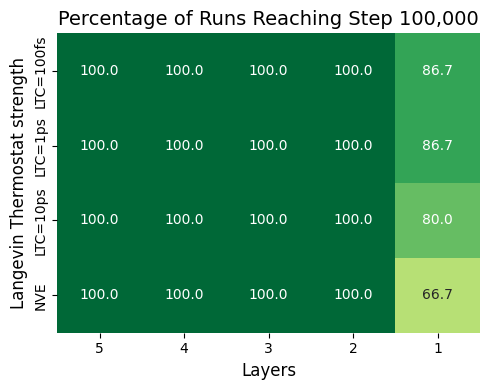

In [127]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Calculate percentage of runs where step == 100,000
for i in range(3):
    if i==0:
        def reduce(group):
            return (group['step'] == 100_000).sum() / len(group) * 100
        title = 'Percentage of Runs Reaching Step 100,000'
        cmap='RdYlGn'
        vmin,vmax=0,100
        save_tag = 'success_ratio'
    elif i==1:
        def reduce(group):
            return (group['avg_iterations']).mean()
        title = 'Avg. Iterations (Forward & Backward)'
        cmap='PiYG_r'
        vmin,vmax=1,10
        save_tag = 'avg_iterations'
    elif i==2:
        def reduce(group):
            return (group['termination_temperature']).mean()
        title = 'Avg. Termination Temperature'
        cmap='PiYG_r'
        vmin,vmax=1,10
        vmin,vmax=None, None
        save_tag = 'termination_temperature'

    # Group by forw_tol and ltc, calculate percentage
    heatmap_data = df_avg.groupby(['ltc', 'forw_tol']).apply(reduce).unstack()
    heatmap_data = heatmap_data.reindex(['LTC=100fs', 'LTC=1ps', 'LTC=10ps', 'NVE'])

    # Create the heatmap
    plt.figure(figsize=(5, 4))
    sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap=cmap, vmin=vmin, vmax=vmax,
                cbar=False,
                # cbar_kws={'label': 'Percentage of runs with step = 100,000 (%)'}
                )
    
    is_explicit = df_avg.forw_tol.max()<0
    
    xlabel = 'Tolerance (Forward & Backward)'
    if is_explicit:
        xlabel = 'Layers'
        locs = plt.gca().get_xticks()
        layer_counts = df_avg.forw_tol.unique()[::-1]
        plt.xticks(ticks=locs, labels=np.abs(layer_counts))


    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel('Langevin Thermostat strength', fontsize=12)
    plt.title(title, fontsize=14)
    plt.tight_layout()
    
    plot_path = '../imlff-paper/figures/energy_conservation'
    pat = proj_path(f'{plot_path}/table_tol_ltc__to__{save_tag}{"__explicit"*is_explicit}.pdf')
    print(pat)
    plt.gcf().savefig(pat, bbox_inches="tight")
    
    
    
    plt.show()
    
    if is_explicit:
        break

### Energy drift plot

In [ ]:
def langevin_energy_rate(gamma, T_system, T_target, n_dof, kB=1.380649e-23):
    """
    Net rate of energy removed from the system by a Langevin thermostat.
    Note: this analysis is experimental and not in submitted paper.

    Parameters
    ----------
    gamma : float
        Coupling strength / friction coefficient (1/time).
    T_system : float
        Current system temperature (K).
    T_target : float
        Target thermostat temperature (K).
    n_dof : int
        Number of degrees of freedom (e.g., 3*N_particles).
    kB : float
        Boltzmann constant. Default is SI (J/K).
        Use 1.0 for reduced units.

    Returns
    -------
    float
        Net energy removal rate (positive = cooling, negative = heating).
    """
    return gamma * n_dof * kB * (T_system - T_target)

100 1.7396177400000003e-07
1000 1.73961774e-08
10000 1.7396177399999999e-09
~/imlff/../imlff-paper/figures/energy_conservation/drift_v_thermostat_E_100_1000_10000.pdf


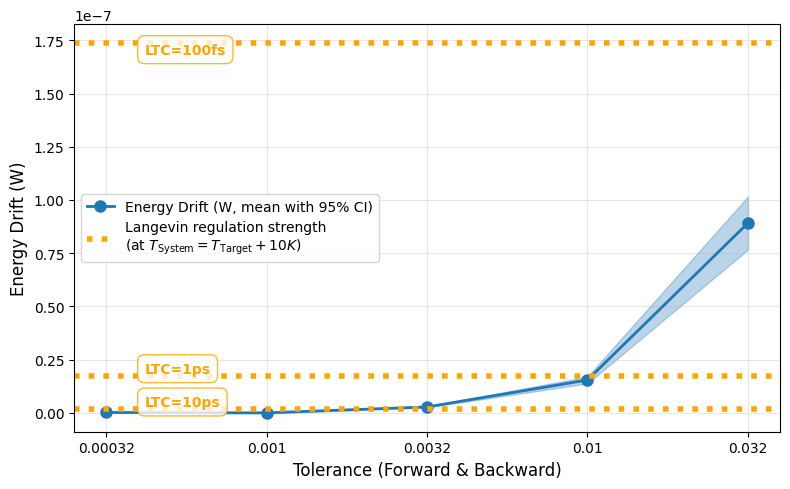

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, LogLocator
import numpy as np

from imlff.data.info import molecule_to_n_atoms

# Boolean options
use_confidence_tunnel = True  # Set to True for filled confidence regions instead of error bars
use_quartiles = True  # Set to True to plot median + Q25/Q75 instead of mean + CI
use_quartiles = False

in_energy = False
in_energy = True

yscale = 'log'

figsize=(7, 4)
figsize=(8, 5)

n_dof=3*molecule_to_n_atoms('Ac-Ala3-NHMe')
kB_kJ = 0.00831445986144858  # kJ/mol/K
KJ_MOL_PER_FS_TO_WATTS = 1000 / 6.022e23 / 1e-15

df_sel = df_avg.copy()
df_sel = df_avg\
    .query('ltc=="NVE"')\
    .query('0 < forw_tol < 0.1')\
    .copy()

lbl_pretty_T = 'Temperature drift (K/fs)'
K_per_step = 2 * (df_avg.temperature - 300) / df_avg.step
df_sel['dT_dt'] = dT_dt = K_per_step * 2 # K per femtosecond

lbl_pretty_E = 'Energy Drift (W)'
drift = 2 * (df_avg.t_e - df_avg.t_e0) / df_avg.step # per .5 fs
# rate_kcal_mol_fs = 2 * drift
# KCAL_MOL_PER_FS_TO_WATTS = 4184 / 6.02214076e23 / 1e-15  # ≈ 6.947e-6
# rate_W = rate_kcal_mol_fs * KCAL_MOL_PER_FS_TO_WATTS
rate_kJ_mol_fs = 2 * drift
KJ_MOL_PER_FS_TO_WATTS = 1000 / 6.022e23 / 1e-15  # 1.661e-6
df_sel['dE_dt'] = dE_dt = rate_kJ_mol_fs * KJ_MOL_PER_FS_TO_WATTS

df_sel['drift'] = df_sel['dE_dt'] if in_energy else df_sel['dT_dt']
lbl_pretty = lbl_pretty_E if in_energy else lbl_pretty_T

if True:
    # Group by forw_tol and ltc
    if use_quartiles:
        grouped = df_sel.groupby(['forw_tol', 'ltc'])['drift'].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
        grouped.columns = ['median', 'q25', 'q75']
    else:
        grouped = df_sel.groupby(['forw_tol', 'ltc'])['drift'].agg(['mean', 'std', 'count'])
        grouped['ci'] = grouped['std'] / np.sqrt(grouped['count']) * 1.96

    # Get unique values
    unique_forw_tol = sorted(df_sel['forw_tol'].unique())
    unique_ltc = sorted(df_sel['ltc'].unique())

    # Create discrete x positions
    x_positions = np.arange(len(unique_forw_tol))

    # Create the plot
    fig, ax = plt.subplots(figsize=figsize)

    # Plot each ltc value with different color
    for ltc_val in unique_ltc:
        means = []
        lower = []
        upper = []
        
        for forw_tol in unique_forw_tol:
            if (forw_tol, ltc_val) in grouped.index:
                if use_quartiles:
                    means.append(grouped.loc[(forw_tol, ltc_val), 'median'])
                    lower.append(grouped.loc[(forw_tol, ltc_val), 'q25'])
                    upper.append(grouped.loc[(forw_tol, ltc_val), 'q75'])
                else:
                    means.append(grouped.loc[(forw_tol, ltc_val), 'mean'])
                    ci = grouped.loc[(forw_tol, ltc_val), 'ci']
                    lower.append(grouped.loc[(forw_tol, ltc_val), 'mean'] - ci)
                    upper.append(grouped.loc[(forw_tol, ltc_val), 'mean'] + ci)
            else:
                means.append(np.nan)
                lower.append(np.nan)
                upper.append(np.nan)
        
        if use_confidence_tunnel:
            # Plot with filled confidence region
            lbl_full = ltc_val
            
            postifx = '(Median with Q25/Q75)' if use_quartiles else '(mean with 95% CI)'
            if lbl_pretty[-1] == ')':
                lbl_full = lbl_pretty[:-1] + ', ' + postifx[1:]
            else:
                lbl_full = lbl_pretty + ' ' + postifx
            
            
            # label=f'Observed Energy drift ({ltc_val})'
            line = ax.plot(x_positions, means, 'o-', markersize=8, linewidth=2, label=lbl_full)
            color = line[0].get_color()
            ax.fill_between(x_positions, lower, upper, alpha=0.3, color=color)
        else:
            # Plot with error bars
            errors = np.array([np.array(means) - np.array(lower), np.array(upper) - np.array(means)])
            ax.errorbar(x_positions, means, yerr=errors,
                        fmt='o-', capsize=5, capthick=2, markersize=8, linewidth=2)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(unique_forw_tol, ha='center')
    ax.set_xlabel('Tolerance (Forward & Backward)', fontsize=12)

    ax.set_ylabel(lbl_pretty, fontsize=12)
    # ax.set_title(title, fontsize=14)

ltcs = [1000, 10000]
ltcs = [100, 1000, 10000]
for i, ltc in enumerate(ltcs):
    gamma = 1.0 / (ltc * 1e-15)  # 1/s
    T_target = 300
    T_system=337
    T_system=307
    
    
    T_system=310
    T_target = 300
    
    
    dE_dt_langevin = langevin_energy_rate(gamma=gamma, T_system=T_system, T_target=T_target, n_dof=n_dof)
    dT_dt_langevin = dE_dt_langevin / (n_dof * kB_kJ * KJ_MOL_PER_FS_TO_WATTS)
    rate_langevin = dE_dt_langevin if in_energy else dT_dt_langevin
    
    # rate > 0 → system is being cooled
    print(ltc, rate_langevin)
    pre = "Energy Outflow" if in_energy else "Temperature Compensation"
    label = f'{pre} through\nLangevin Thermostats at {T_system}K'
    label = f'{pre} when system is at\n{T_system-T_target}K above Langevin Thermostats target'
    label = f'Langevin Thermostat Regulation\nwhen system is {T_system-T_target}K above target temperature'
    label = f'Langevin Regulation strength\nat {T_system-T_target}K above target temperature'
    label = f'Langevin Regulation strength with\nsystem temperature {T_system-T_target}K above target'
    label = 'Langevin regulation strength\n' + fr'(at $T_\text{"{System}"} = T_\text{"{Target}"} + {10}K$)'
    ax.axhline(rate_langevin, color='orange', linestyle=':', linewidth=4, label=label if i==0 else None)
    
    # Add label on top right of the horizontal line
    label = f'LTC={ int(ltc/1000)}ps at +{T_system-T_target:.0f}K above Target: {rate_langevin:.1e} W'
    if ltc >= 1000:
        label = f'LTC={ltc/1000:g}ps'
    else:
        label = f'LTC={ltc:g}fs'
    # Get current axis limits
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    if len(ltcs)==2: # plot above line
        x_offset = (xlim[1] - xlim[0]) * 0.02  # 2% of x-range to the right
        y_offset = (ylim[1] - ylim[0]) * 0.03
        verticalalignment='bottom'
    elif len(ltcs)==3: # plot on line
        x_offset = (xlim[1] - xlim[0]) * 0.1
        y_offset = 0
        verticalalignment='top' if i==0 else 'bottom'
    else:
        raise ValueError
    
    ax.text(xlim[0] + x_offset, rate_langevin + y_offset, label,  # offset right and up
            verticalalignment=verticalalignment, horizontalalignment='left',
            color='orange', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='orange', alpha=0.8))


if yscale=='symlog:':
    ax.set_yscale('symlog', linthresh=0.01)
else:
    ax.set_yscale(yscale)
    
ax.legend()
# ax.yaxis.set_major_locator(FixedLocator([-1e-3, 0, 1e-3, 1e-2]))
ax.grid(True, alpha=0.3, which='major')

plt.tight_layout()
plot_path = '../imlff-paper/figures/energy_conservation'
filename = 'drift_v_thermostat'
filename += '_E' if in_energy else '_T'
if yscale is not None:
    filename += '_' + yscale
ltcs = tuple(sorted(ltcs))
if ltcs != (1000, 10000):
    for ltc in ltcs:
        filename += f'_{ltc}'
pat = proj_path(f'{plot_path}/{filename}.pdf')
print(pat)
fig.savefig(pat, bbox_inches="tight")
plt.show()